In [1]:
import json
import math
import os
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.cm as cm
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
from PIL import Image
from torch import nn
from torch.nn import functional as F

# training.ipynb vive en experimentation/, y el paquete `modules` quedó en la raíz del proyecto
project_root = Path.cwd().resolve().parent
sys.path.append(str(project_root))

from modules.visualizations import visualize_attention, visualize_attention_on_images
from modules.model import ViTForClassfication
from modules.datasets import AwA2Dataset, CelebADataset, CIFAR10Dataset
from modules.effective_rank import effective_rank
from modules.cka import linear_cka
import torch
from torch import nn, optim
from modules.experiments import save_experiment, save_checkpoint
import logging
from rich.logging import RichHandler
from tqdm.auto import tqdm

# Apuntar siempre al mlflow.db local (Jupyter ejecuta desde el directorio del notebook)
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Logging con colores vía rich: nivel, timestamp y mensaje coloreados por severidad.
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    datefmt="[%X]",
    handlers=[RichHandler(rich_tracebacks=True, show_path=False)],
    force=True,
)
logger = logging.getLogger("vit_training")

In [2]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

In [3]:
DATASET_NAME = "AwA2"  #@param ["CIFAR10", "CelebA", "AwA2"] {type:"string"}

# Mismo tamaño de entrada (32x32) para las tres, así los checkpoints son comparables entre datasets
# con la misma arquitectura. AwA2 usa el cache local (ver modules.datasets.prepare_awa2_cache).
DATASET_REGISTRY = {
    "CIFAR10": lambda: CIFAR10Dataset(),
    "CelebA": lambda: CelebADataset(),
    "AwA2": lambda: AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2")),
}
dataset = DATASET_REGISTRY[DATASET_NAME]()
trainloader, testloader, classes = dataset.get_loaders(batch_size=128, num_workers=4)
logger.info(f"Dataset {dataset.name} listo: {len(dataset.trainset)} train / {len(dataset.testset)} test, {dataset.n_classes} clases.")

[11:06:55] INFO     Dataset AwA2 listo: 29854 train / 7468 test, 50 clases.

In [4]:
dataset

In [5]:
INDICES = [10, 12, 34, 46, 100]

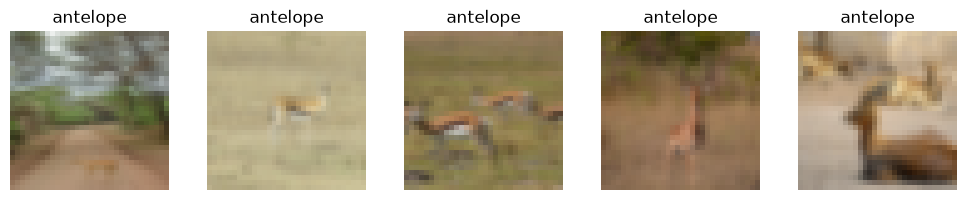

In [6]:
dataset.visualize_sample(indices=INDICES, set="train")

In [7]:
config = {
    "patch_size": 4,  # Input image size: 128x128 -> 32x32 patches
    "hidden_size": 48,
    "num_hidden_layers": 4,
    "num_attention_heads":4,
    "intermediate_size": 4 * 48, # 4 * hidden_size
    "hidden_dropout_prob": 0.0,
    "attention_probs_dropout_prob": 0.0,
    "initializer_range": 0.02,
    "image_size": 32,
    "num_classes": dataset.n_classes,  # 40 atributos binarios de CelebA (multi-label)
    "num_channels": 3,
    "qkv_bias": True,
    "use_faster_attention": False,
}

model = ViTForClassfication(config).to(device)


In [8]:
dataset.get_samples_from_indices(INDICES)[0].shape

torch.Size([5, 3, 32, 32])

In [9]:
random_input = dataset.get_samples_from_indices(INDICES)[0].to(device)
logits, attention_maps = model(random_input, output_attentions=True)

In [10]:
attention_maps[0].shape

torch.Size([5, 4, 65, 65])

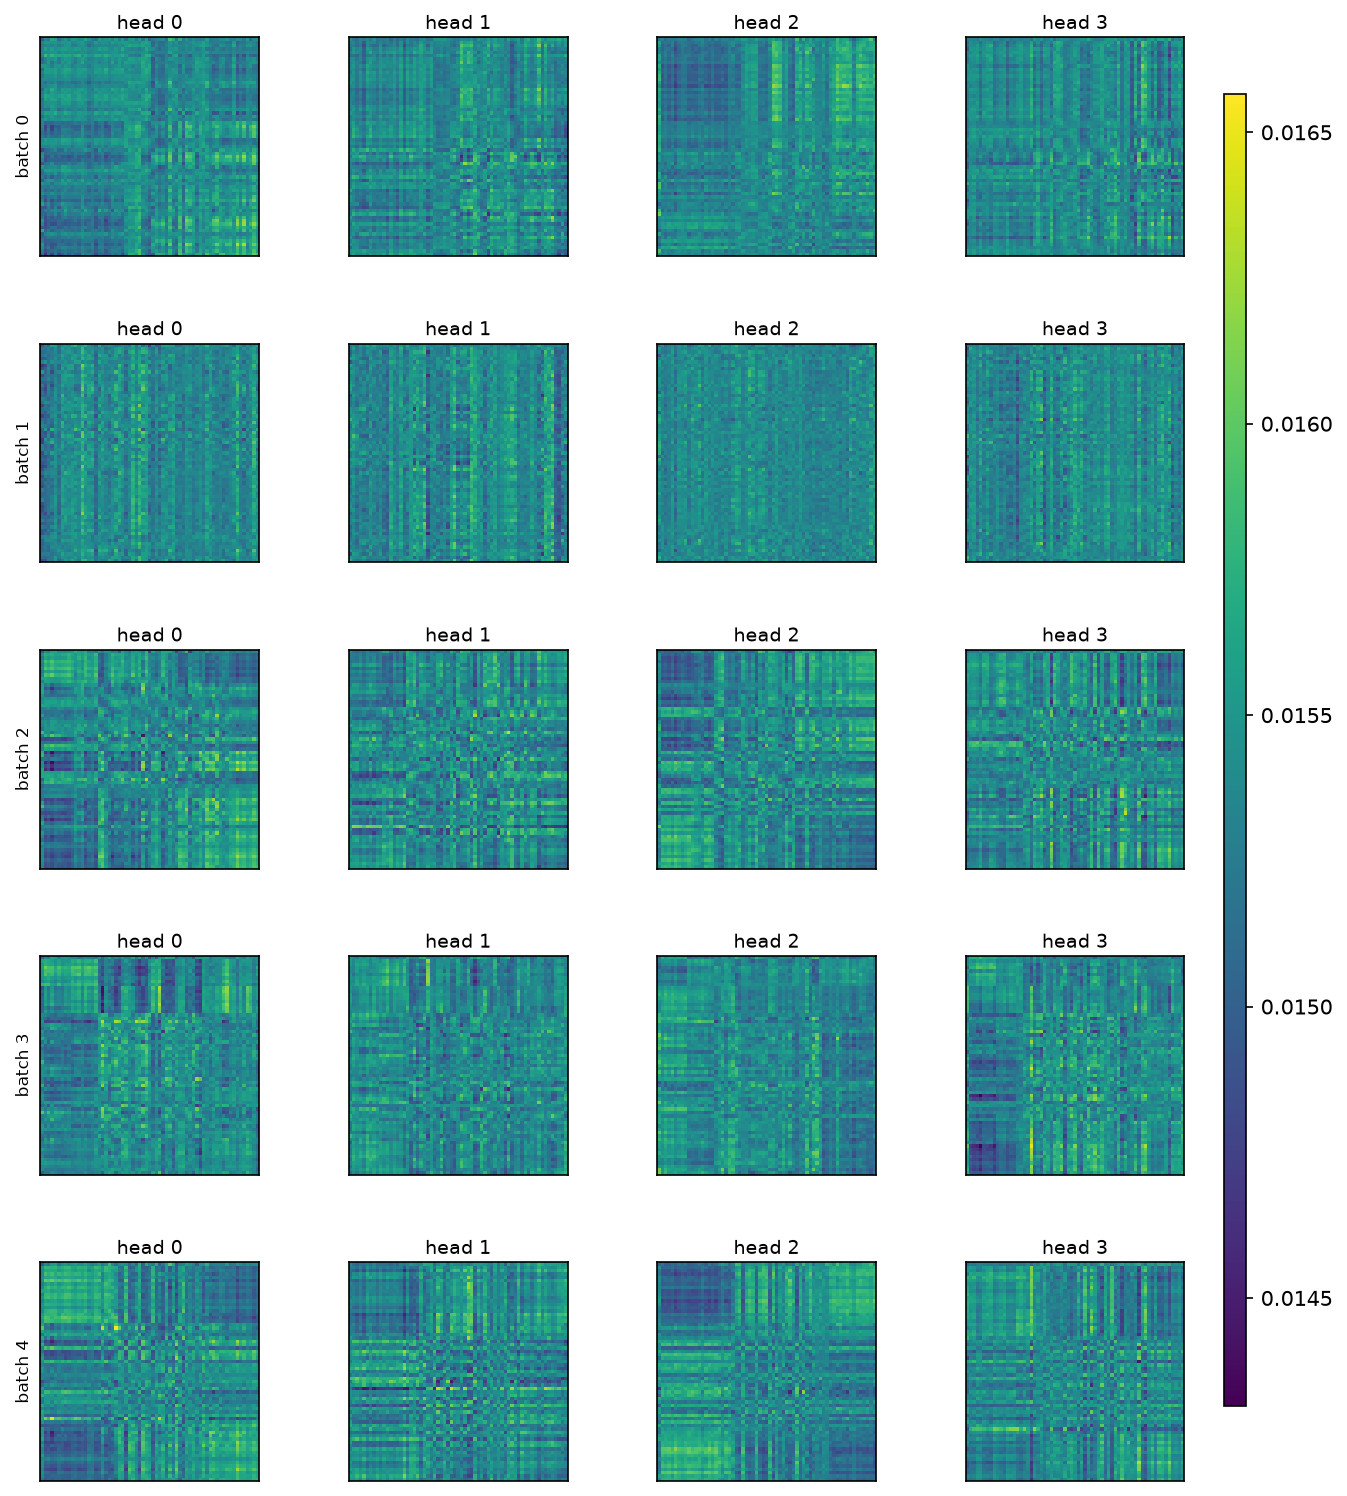

In [11]:
visualize_attention(attention_maps[0])

In [12]:
attention_maps[0].shape

torch.Size([5, 4, 65, 65])

In [13]:
dataset.get_samples_from_indices(INDICES, set="training")[0].shape

torch.Size([5, 3, 32, 32])

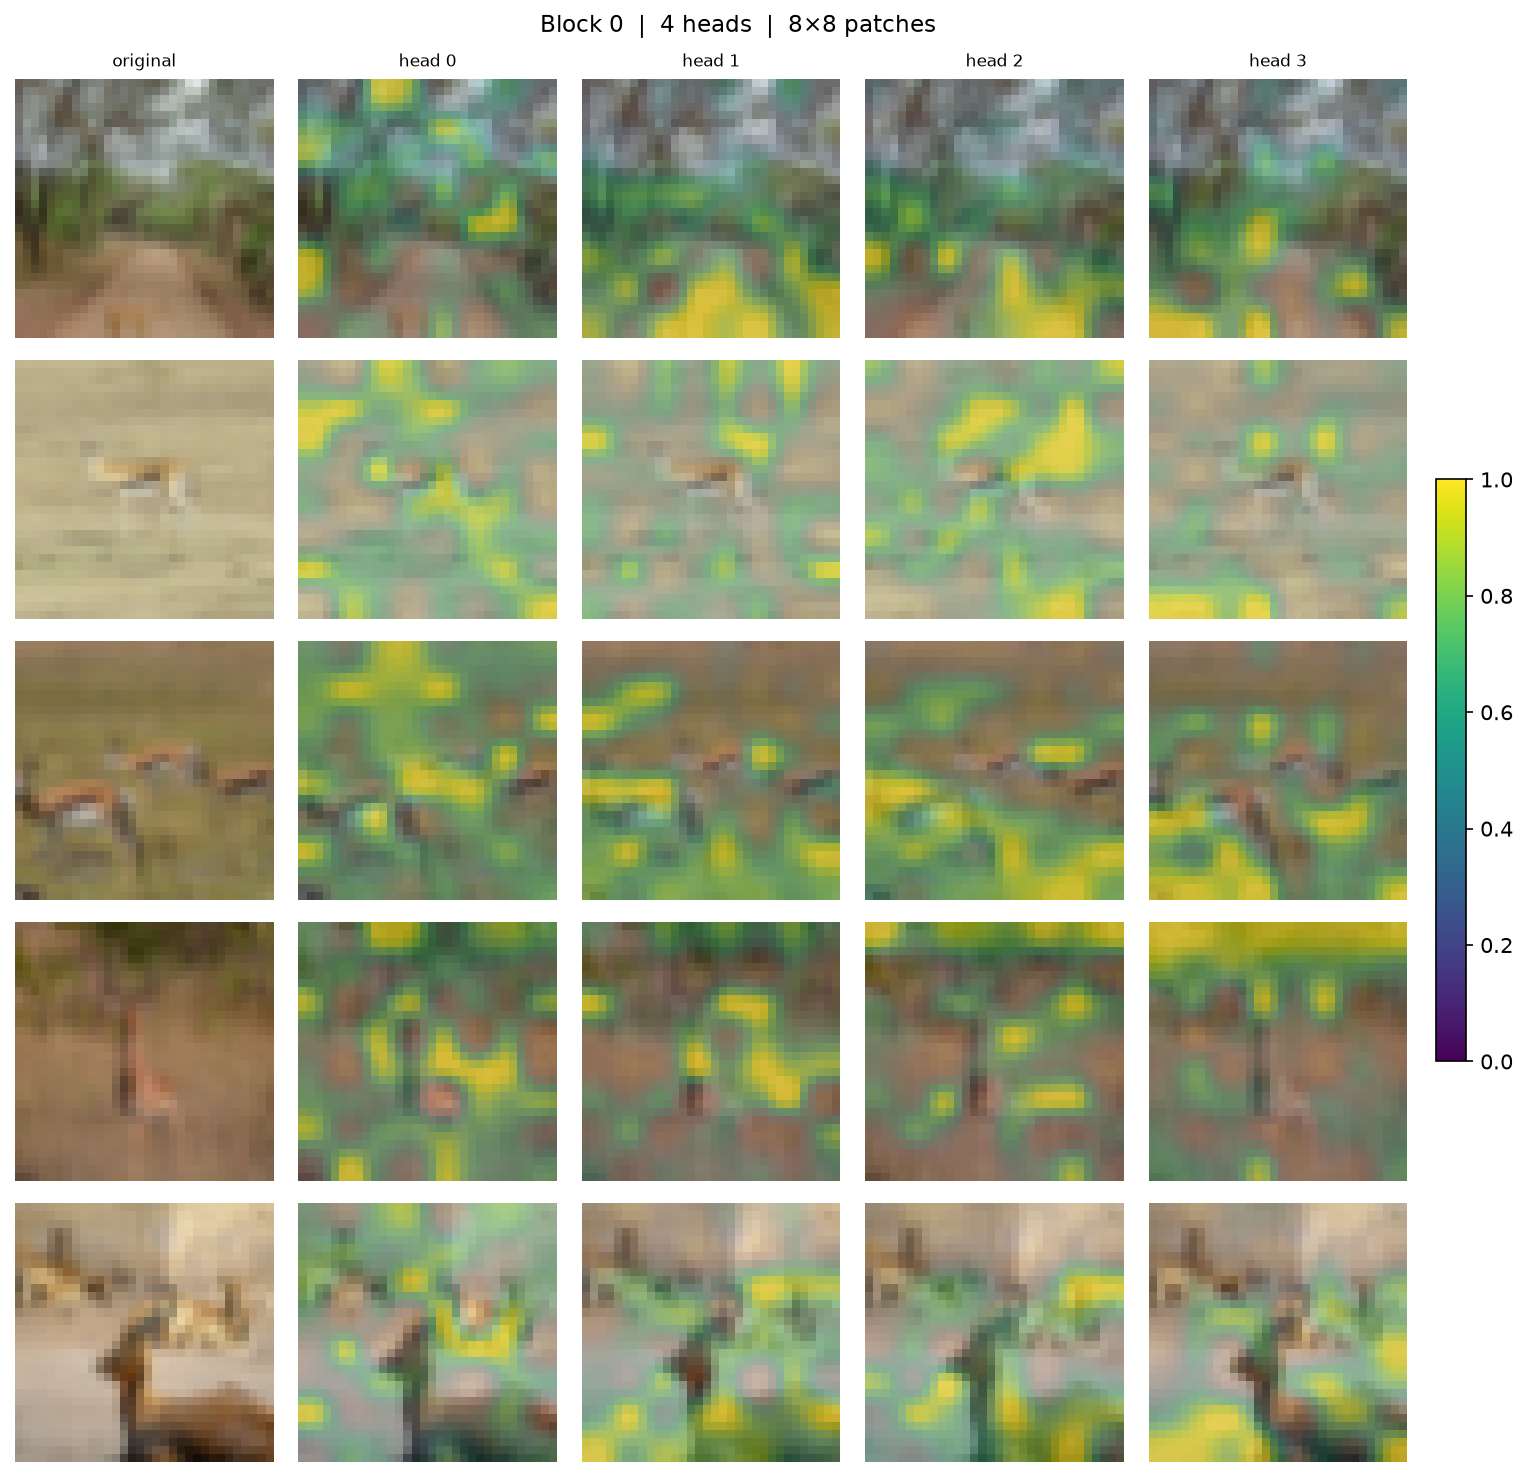

In [14]:
visualize_attention_on_images(attention_maps[0], dataset.get_samples_from_indices(INDICES, set='training')[0])[0]

In [15]:
is_interpretable = True #@param {type:"boolean"}
epochs = 15 #@param {type: "integer"}
exp_name = f'vit-with-{epochs}-epochs{"-interpretable" if is_interpretable else ""}-{dataset.name}' #@param {type:"string"}
batch_size = 32 #@param {type: "integer"}
lr = 1e-2  #@param {type: "number"}
save_model_every = 0 #@param {type: "integer"}
lambda_loss = 0.1 #@param {type: "number"}

mlflow.set_experiment(exp_name)

config = {
    "patch_size": 4,  # Input image size: 128x128 -> 32x32 patches
    "hidden_size": 48,
    "num_hidden_layers": 4,
    "num_attention_heads": 4,
    "intermediate_size": 4 * 48, # 4 * hidden_size
    "hidden_dropout_prob": 0.0,
    "attention_probs_dropout_prob": 0.0,
    "initializer_range": 0.02,
    "image_size": 32,
    "num_classes": dataset.n_classes,  # 40 atributos binarios de CelebA (multi-label)
    "num_channels": 3,
    "qkv_bias": True,
    "use_faster_attention": False,
}
assert config["hidden_size"] % config["num_attention_heads"] == 0
assert config['intermediate_size'] == 4 * config['hidden_size']
assert config['image_size'] % config['patch_size'] == 0

In [16]:
# Trainer y la loss de penalización viven en modules/training.py (reutilizado también por
# notebooks/25092026_awa2_probing/train_awa2.ipynb) para no mantener dos copias.
from modules.training import Trainer, interpretability_loss

In [17]:
save_model_every_n_epochs = save_model_every
logger.info(f"Recargando loaders con batch_size={batch_size}...")
trainloader, testloader, _ = dataset.get_loaders(batch_size=batch_size, num_workers=4)
model = ViTForClassfication(config)
logger.info(f"Modelo ViT creado: {sum(p.numel() for p in model.parameters()):,} parámetros.")

[11:07:04] INFO     Recargando loaders con batch_size=32...

           INFO     Modelo ViT creado: 121,058 parámetros.

In [18]:
optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
# CelebA es multi-label (40 atributos binarios independientes por imagen), no
# clasificación de una sola clase: BCEWithLogitsLoss trata cada salida del
# clasificador como un sigmoide binario independiente.
loss_fn = nn.BCEWithLogitsLoss() if dataset.multi_label else nn.CrossEntropyLoss()
trainer = Trainer(model, optimizer, loss_fn, exp_name, device=device, config=config,
                  is_interpretable=is_interpretable, lambda_loss=lambda_loss, batch_size=batch_size, lr=lr,
                  dataset=dataset, log_indices=INDICES, base_dir="experiments")
trainer.train(trainloader, testloader, epochs, save_model_every_n_epochs=save_model_every_n_epochs)

[11:07:05] INFO     Iniciando entrenamiento 'vit-with-15-epochs-interpretable-AwA2': 15 épocas, batch_size=32,     
                    lr=0.01, device=mps

Épocas:   0%|          | 0/15 [00:00<?, ?epoch/s]

Época 1 [train]:   0%|          | 0/933 [00:05<?, ?batch/s]

Época 1 [eval]:   0%|          | 0/234 [00:05<?, ?batch/s]

[11:08:23] INFO     Epoch 1/15 - Train Loss: 3.2724, Train Diversity Loss: 0.1759, Test Loss: 3.1080, Test         
                    Accuracy: 0.1204

Época 2 [train]:   0%|          | 0/933 [00:05<?, ?batch/s]

... (39 outputs left out)

Época 15 [eval]:   0%|          | 0/234 [00:05<?, ?batch/s]

[11:28:53] INFO     Epoch 15/15 - Train Loss: 2.3467, Train Diversity Loss: 0.0126, Test Loss: 2.3990, Test        
                    Accuracy: 0.2957

           INFO     Entrenamiento finalizado. Modelo y métricas guardados para                                     
                    'vit-with-15-epochs-interpretable-AwA2'.

{'cls_loss': 2.664613493487366,
 'interpretability_loss': 0.008381632677554034,
 'attn_erank': 3.763076207576654,
 'total_loss': 2.398990244946928,
 'accuracy': 0.29566148901981787}

In [ ]:
mlflow.end_run()

In [ ]:
current_date = datetime.now().strftime("%Y-%m-%d-%H-%M-%S")
model_path = f"vit_final_{dataset.name}_{current_date}_{'interpretable' if is_interpretable else 'non_interpretable'}.pt"
torch.save(model.state_dict(), model_path)
logger.info(f"Modelo final guardado en {model_path}")